In [1]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
meta = pd.read_csv('combined_sample_metadata.csv').set_index('file')
metacols = list(meta.columns)
metacols

['bead', 'sample', 'type', 'model', 'age', 'original_file']

In [3]:
# --- per-sample QC cutoffs (based on qc_cutoff_stats.csv) ---
MT_DEFAULT   = 10
RIBO_DEFAULT = 20 

mt_by_model = {
    'LA1': 20,                                   # shallow tumours: median cell sits at ~11-12% mt
    'egfr Basal': 20, 'egfr Club': 20,           # lineage files were already filtered at mt<20
    'egfr AT2': 20, 'wt': 20,
}
mt_by_sample = {                                 # sorted populations with a long dying-cell tail
    'Organoid_Fresh': 15,
    'p63 Trace_d14': 15, 'p63 Trace_m3': 15, 'p63 Trace_m5': 15,
}
ribo_by_model = {
    'LA1': 40,         # 35-37% of cells exceed 20; tumour cells run high on ribo
    'KPT': 40,         # only 5% exceed 20, but keep the two tumour models consistent
}

def mt_cutoff(data):
    """Sample-level override > model-level override > default."""
    return mt_by_sample.get(data['sample'], mt_by_model.get(data['model'], MT_DEFAULT))
def ribo_cutoff(data):
    return ribo_by_model.get(data['model'], RIBO_DEFAULT)

In [4]:
adatas = []

for file, data in meta.iterrows():
    path = Path(file)
    if not path.exists():
        raise FileNotFoundError(
            f'{file} is listed but not found'
        )

    adata = sc.read_h5ad(file)
    adata.var_names_make_unique()

    for column in metacols:
        adata.obs[column] = data[column]

    sc.pp.filter_cells(adata, min_genes=200)

    adata.var['mt']   = adata.var_names.str.startswith('mt-')
    adata.var['ribo'] = adata.var_names.str.startswith(('Rpl', 'Rps'))

    sc.pp.calculate_qc_metrics(
        adata, qc_vars=['mt', 'ribo'], percent_top=None,
        log1p=False, inplace=True
    )
    mt_cut = mt_cutoff(data)
    adata.obs['mt_cut']   = mt_cut
    ribo_cut = ribo_cutoff(data)
    adata.obs['ribo_cut'] = ribo_cut

    upperlim = np.percentile(adata.obs['n_genes_by_counts'], 99)
    lowerlim = np.percentile(adata.obs['n_genes_by_counts'], 2)

    adata = adata[(adata.obs['n_genes_by_counts'] >= lowerlim)
                  & (adata.obs['n_genes_by_counts'] <= upperlim)
                  & (adata.obs['pct_counts_mt'] < mt_cut)
                  & (adata.obs['pct_counts_ribo'] < ribo_cut)
                  ].copy()

    # 10x barcodes repeat across samples - suffix them so each cell stays
    # traceable to its sample after concatenation
    adata.obs_names = adata.obs_names.astype(str) + '_' + str(data['sample'])

    adatas.append(adata)
    print(adata.shape, file)

c:\ProgramData\anaconda3\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


(8925, 55359) C:\Users\G20748795\Desktop\lab\Tumor\WT_1.h5ad


c:\ProgramData\anaconda3\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


(6002, 55359) C:\Users\G20748795\Desktop\lab\Tumor\Sox2_1.h5ad


c:\ProgramData\anaconda3\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


(7684, 55361) C:\Users\G20748795\Desktop\lab\Tumor\WT_2.h5ad


... (18 outputs left out)

c:\ProgramData\anaconda3\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


(1044, 27998) C:\Users\G20748795\Desktop\lab\Tumor\Organoid_Day 10.h5ad


c:\ProgramData\anaconda3\Lib\site-packages\anndata\_core\anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


(5023, 27998) C:\Users\G20748795\Desktop\lab\Tumor\Organoid_Day 14.h5ad
(4338, 23811) C:\Users\G20748795\Desktop\lab\Tumor\egfr_bsc_10wk_control_trachea.h5ad
(2076, 23811) C:\Users\G20748795\Desktop\lab\Tumor\egfr_bsc_20wk_control_lung.h5ad
(8769, 23811) C:\Users\G20748795\Desktop\lab\Tumor\egfr_bsc_20wk_control_trachea.h5ad
(8181, 23811) C:\Users\G20748795\Desktop\lab\Tumor\egfr_cc10_10wk_control.h5ad
(3190, 23811) C:\Users\G20748795\Desktop\lab\Tumor\egfr_cc10_3wk_control.h5ad
(4351, 23811) C:\Users\G20748795\Desktop\lab\Tumor\egfr_spc_10wk_control.h5ad
(932, 23811) C:\Users\G20748795\Desktop\lab\Tumor\egfr_spc_3wk_control.h5ad
(855, 23811) C:\Users\G20748795\Desktop\lab\Tumor\egfr_spc_3wk_control_pilot.h5ad
(1733, 23811) C:\Users\G20748795\Desktop\lab\Tumor\wt_bsc_10wk_control_trachea.h5ad
(1144, 23811) C:\Users\G20748795\Desktop\lab\Tumor\wt_cc10_3wk_control.h5ad
(923, 23811) C:\Users\G20748795\Desktop\lab\Tumor\wt_spc_3wk_control.h5ad


In [5]:
adata = ad.concat(adatas, join='outer')
print(adata)
sc.pp.filter_genes(adata, min_cells=3)      # added after concatenation in case we dont lose valuable genes in small samples
adata

AnnData object with n_obs × n_vars = 347371 × 64009
    obs: 'bead', 'sample', 'type', 'model', 'age', 'original_file', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'mt_cut', 'ribo_cut', 'batch', 'nCount_RNA', 'nFeature_RNA', 'nCount_SCT', 'nFeature_SCT', 'experiment', 'condition', 'treatment', 'mutation', 'timepoint', 'lineage', 'celltype_1_label', 'KAC_Han_score', 'sig14_score'
    layers: 'ambiguous', 'matrix', 'spliced', 'unspliced'


AnnData object with n_obs × n_vars = 347371 × 38891
    obs: 'bead', 'sample', 'type', 'model', 'age', 'original_file', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'mt_cut', 'ribo_cut', 'batch', 'nCount_RNA', 'nFeature_RNA', 'nCount_SCT', 'nFeature_SCT', 'experiment', 'condition', 'treatment', 'mutation', 'timepoint', 'lineage', 'celltype_1_label', 'KAC_Han_score', 'sig14_score'
    var: 'n_cells'
    layers: 'ambiguous', 'matrix', 'spliced', 'unspliced'

In [6]:
adata.layers['counts'] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

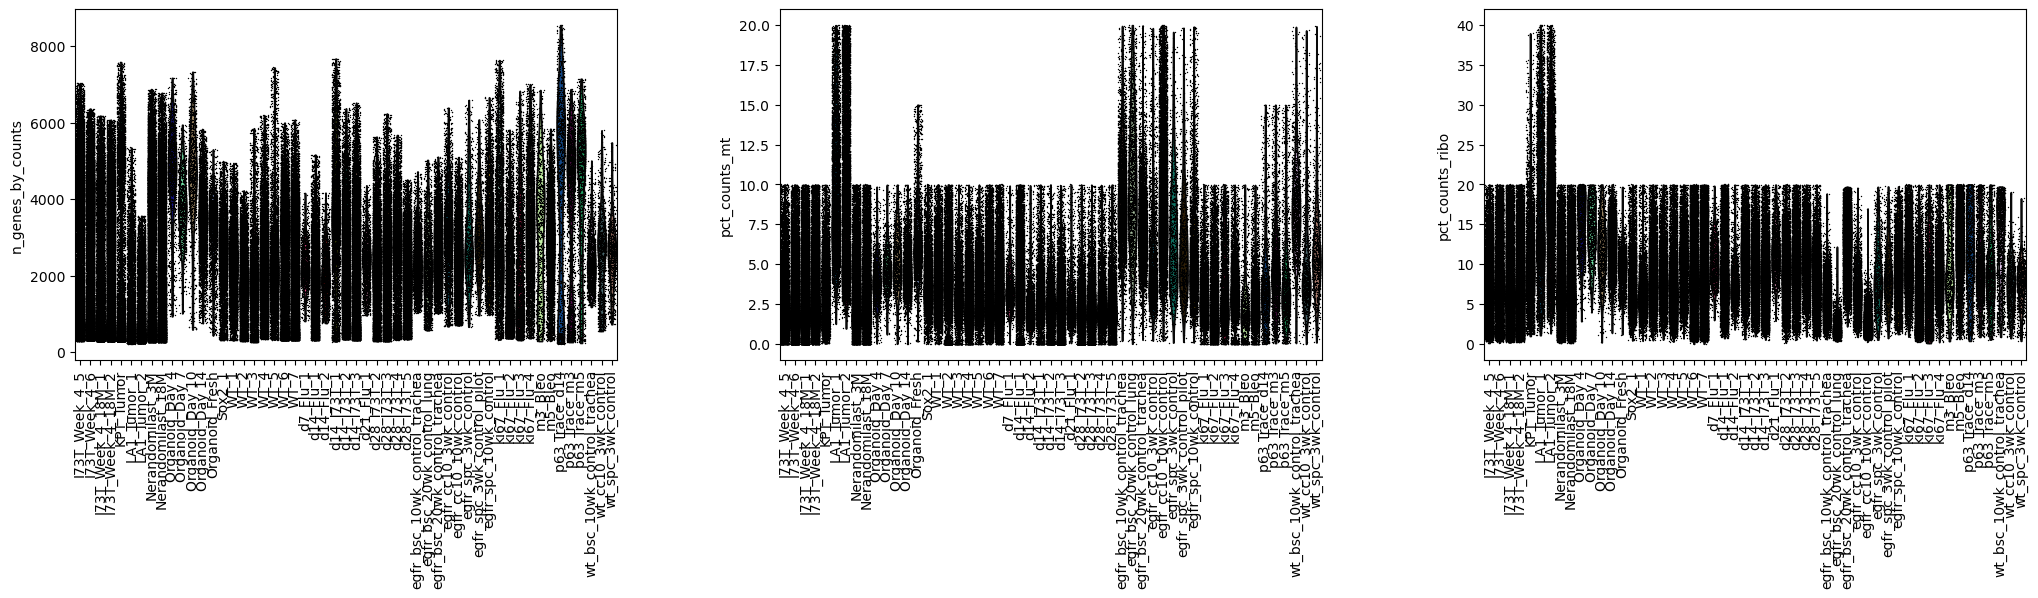

In [7]:
sc.pl.violin(
    adata,
    ['n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribo'],
    groupby='sample', rotation=90, jitter=0.4
)

In [8]:
adata.write_h5ad('preprocessed.h5ad')